In [ ]:
#1. LOADING
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Cukup 1 kali load. Dataset ini tidak punya file train/test terpisah,
# jadi pembagian train/test dilakukan nanti di bagian Splitting.
df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
#2. CLEANING
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [3]:
# Statistik deskriptif (include='all' supaya kolom teks ikut tampil)
df.describe(include="all")

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [4]:
# Cek missing value
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

director      2634
cast           825
country        831
date_added      10
rating           4
duration         3
dtype: int64

In [5]:
# Perbaiki 3 baris yang rating-nya tertukar dengan duration
salah = df['rating'].str.contains('min', na=False)
df.loc[salah, 'duration'] = df.loc[salah, 'rating']
df.loc[salah, 'rating'] = np.nan

# Isi missing value kolom kategorikal dengan 'Unknown'
for col in ['director', 'cast', 'country', 'rating']:
    df[col] = df[col].fillna('Unknown')

# date_added -> datetime (ada spasi di depan pada beberapa baris, jadi di-strip)
df['date_added'] = pd.to_datetime(df['date_added'].str.strip(), format='%B %d, %Y', errors='coerce')

# date_added yang hilang (10 baris) diisi median
df['date_added'] = df['date_added'].fillna(df['date_added'].median())

df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64

In [6]:
# Cek & hapus duplikat
print("Jumlah duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Shape setelah drop duplikat:", df.shape)

Jumlah duplikat: 0
Shape setelah drop duplikat: (8807, 12)


In [7]:
fe = pd.DataFrame()
fe['type']          = df['type']                                   # TARGET
fe['release_year']  = df['release_year']
fe['year_added']    = df['date_added'].dt.year
fe['month_added']   = df['date_added'].dt.month
fe['rating']        = df['rating']
fe['country_main']  = df['country'].str.split(',').str[0].str.strip()
fe['n_countries']   = df['country'].apply(lambda x: 0 if x == 'Unknown' else len(x.split(',')))
fe['n_cast']        = df['cast'].apply(lambda x: 0 if x == 'Unknown' else len(x.split(',')))
fe['n_genres']      = df['listed_in'].apply(lambda x: len(x.split(',')))
fe['has_director']  = (df['director'] != 'Unknown').astype(int)
fe['desc_length']   = df['description'].str.len()
fe['title_length']  = df['title'].str.len()

# country: ambil 10 teratas, sisanya 'Other' (supaya kolom one-hot tidak meledak)
top_country = fe['country_main'].value_counts().head(10).index
fe['country_main'] = fe['country_main'].where(fe['country_main'].isin(top_country), 'Other')

fe.head()

,type,release_year,year_added,month_added,rating,country_main,n_countries,n_cast,n_genres,has_director,desc_length,title_length
0,Movie,2020,2021,9,PG-13,United States,1,0,1,1,152,20
1,TV Show,2021,2021,9,TV-MA,Other,1,19,3,0,147,13
2,TV Show,2021,2021,9,TV-MA,Unknown,0,9,3,1,146,9
3,TV Show,2021,2021,9,TV-MA,Unknown,0,0,2,0,147,21
4,TV Show,2021,2021,9,TV-MA,India,1,8,3,0,152,12


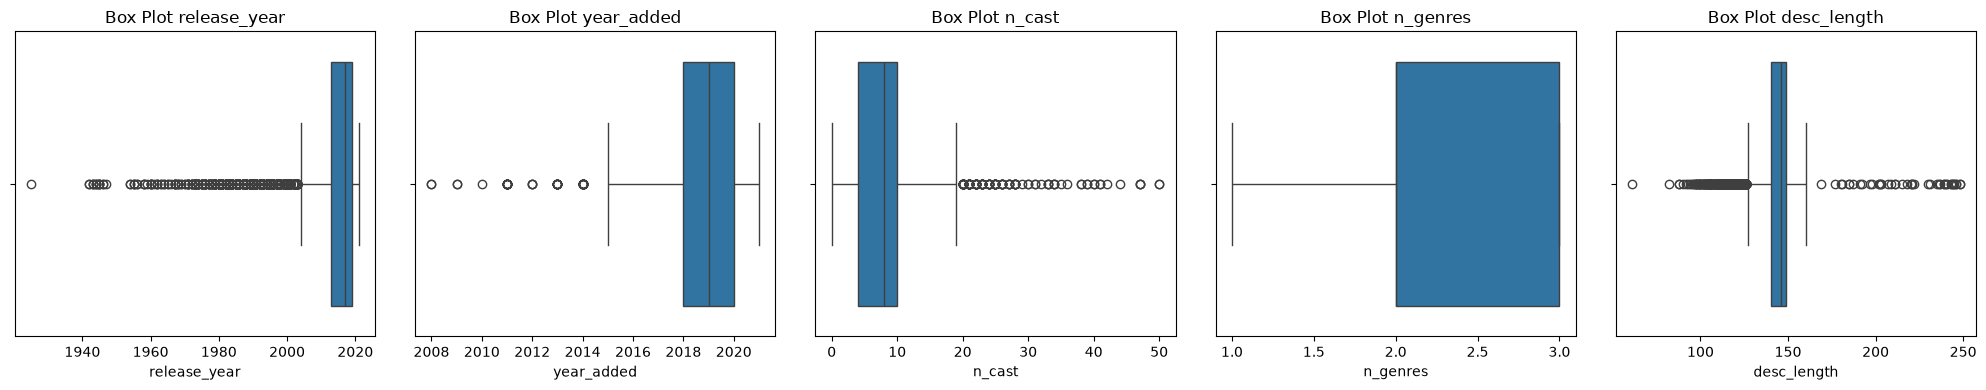

In [8]:
num_cols = ['release_year', 'year_added', 'n_cast', 'n_genres', 'desc_length']
fig, axes = plt.subplots(1, len(num_cols), figsize=(20, 4))
for ax, f in zip(axes, num_cols):
    sns.boxplot(x=fe[f], ax=ax)
    ax.set_title(f'Box Plot {f}')
plt.tight_layout()
plt.show()

In [9]:
# Cek jumlah outlier (IQR) hanya sebagai informasi
Q1 = fe[num_cols].quantile(0.25)
Q3 = fe[num_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_mask = (fe[num_cols] < (Q1 - 1.5 * IQR)) | (fe[num_cols] > (Q3 + 1.5 * IQR))
print(outlier_mask.sum())

release_year    719
year_added       56
n_cast          123
n_genres          0
desc_length     564
dtype: int64


In [10]:
# Outlier dibatasi (capping) ke batas IQR HANYA untuk fitur yang memang bisa ekstrem (n_cast, desc_length),
# bukan untuk release_year / year_added (itu data valid)
for f in ['n_cast', 'desc_length']:
    lower = Q1[f] - 1.5 * IQR[f]
    upper = Q3[f] + 1.5 * IQR[f]
    fe[f] = fe[f].clip(lower, upper)

In [11]:
# Target: Movie = 0, TV Show = 1
y = fe['type'].map({'Movie': 0, 'TV Show': 1})

# Fitur: one-hot untuk kolom kategorikal
X = pd.get_dummies(fe.drop(columns='type'), columns=['rating', 'country_main'], drop_first=True)
X = X.astype(float)

print("Shape X:", X.shape)
print(y.value_counts())
X.head()

Shape X: (8807, 33)
type
0    6131
1    2676
Name: count, dtype: int64


,release_year,year_added,month_added,n_countries,n_cast,n_genres,has_director,desc_length,title_length,rating_NC-17,...,country_main_France,country_main_India,country_main_Japan,country_main_Mexico,country_main_Other,country_main_South Korea,country_main_Spain,country_main_United Kingdom,country_main_United States,country_main_Unknown
0,2020.0,2021.0,9.0,1.0,0.0,1.0,1.0,152.0,20.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,2021.0,2021.0,9.0,1.0,19.0,3.0,0.0,147.0,13.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,2021.0,2021.0,9.0,0.0,9.0,3.0,1.0,146.0,9.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2021.0,2021.0,9.0,0.0,0.0,2.0,0.0,147.0,21.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2021.0,2021.0,9.0,1.0,8.0,3.0,0.0,152.0,12.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


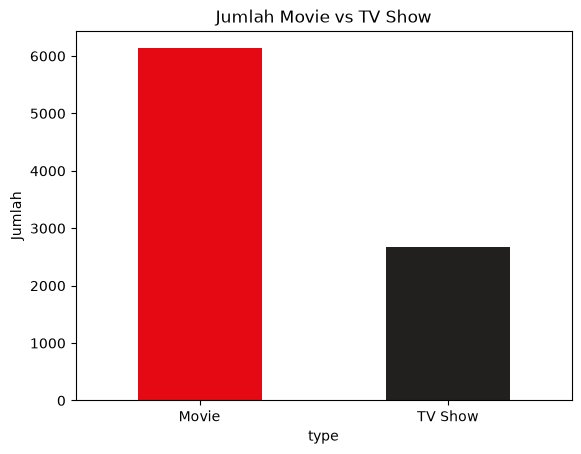

In [ ]:
#3. EDA
df['type'].value_counts().plot(kind='bar', color=['#e50914', '#221f1f'])
plt.title('Jumlah Movie vs TV Show')
plt.ylabel('Jumlah')
plt.xticks(rotation=0)
plt.show()

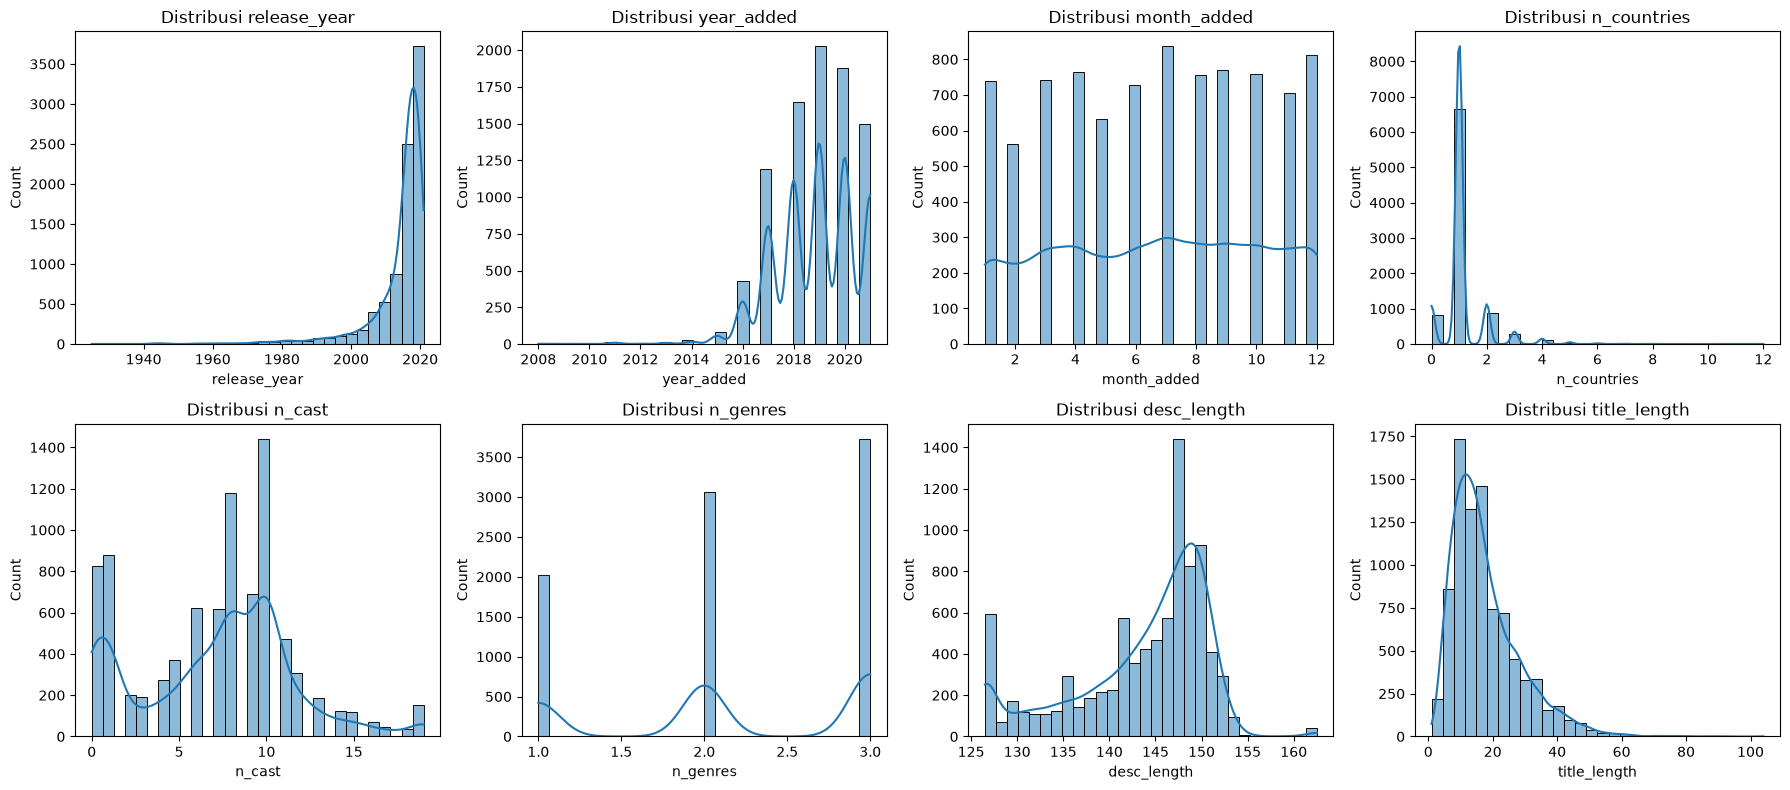

In [13]:
# Distribusi fitur numerik
cols = ['release_year', 'year_added', 'month_added', 'n_countries', 'n_cast', 'n_genres', 'desc_length', 'title_length']
plt.figure(figsize=(18, 8))
for i, c in enumerate(cols, 1):
    plt.subplot(2, 4, i)
    sns.histplot(fe[c], kde=True, bins=30)
    plt.title(f'Distribusi {c}')
plt.tight_layout()
plt.show()

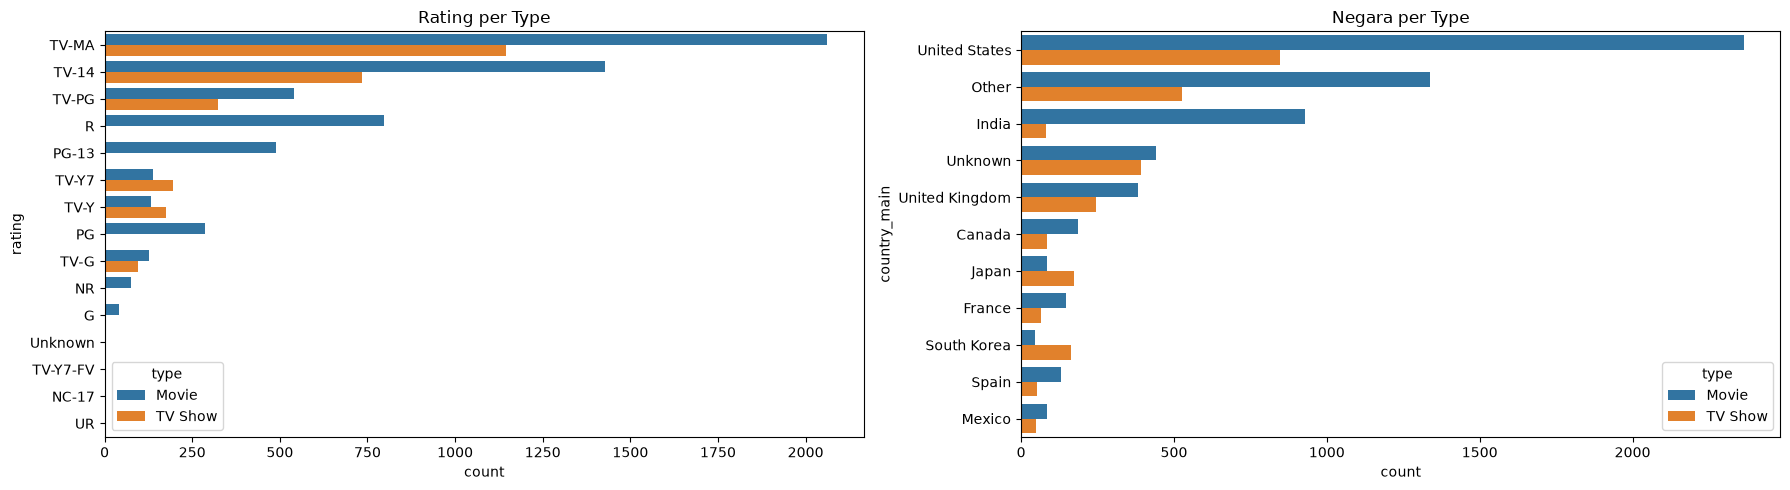

In [14]:
# Distribusi fitur kategorikal per type
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sns.countplot(data=fe, y='rating', hue='type', order=fe['rating'].value_counts().index, ax=axes[0])
axes[0].set_title('Rating per Type')
sns.countplot(data=fe, y='country_main', hue='type', order=fe['country_main'].value_counts().index, ax=axes[1])
axes[1].set_title('Negara per Type')
plt.tight_layout()
plt.show()

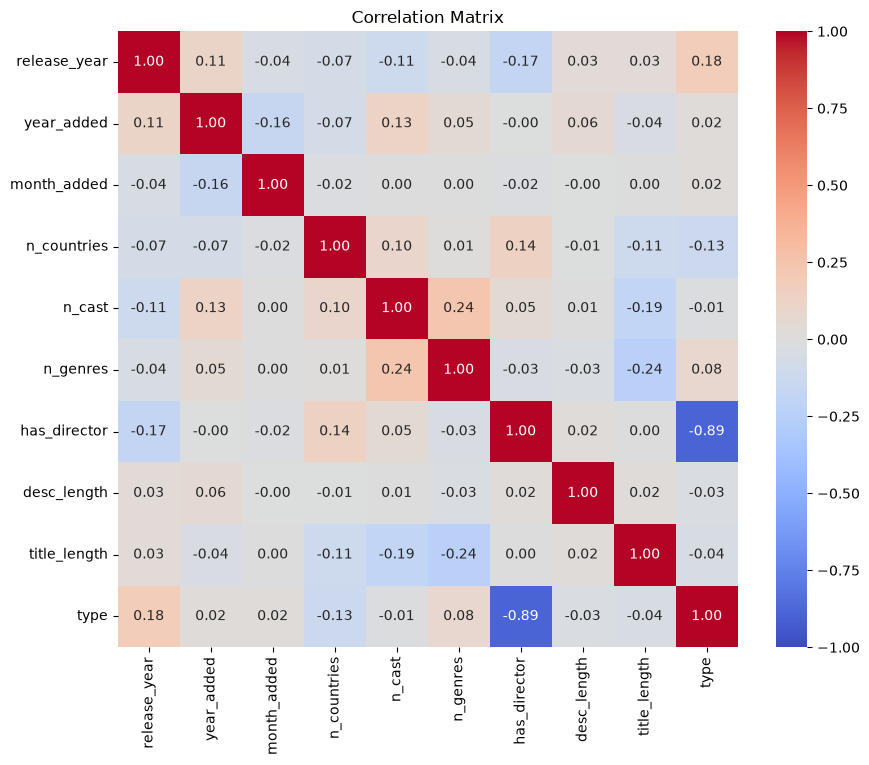

In [15]:
data_corr = X[['release_year','year_added','month_added','n_countries','n_cast','n_genres','has_director','desc_length','title_length']].copy()
data_corr['type'] = y
plt.figure(figsize=(10, 8))
sns.heatmap(data_corr.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

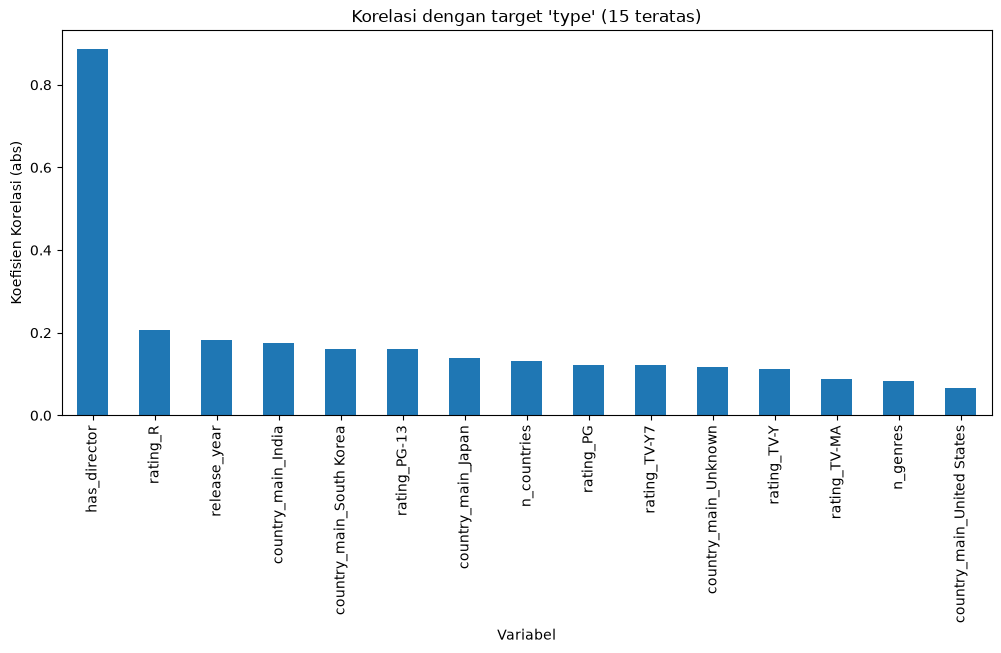

In [16]:
target_corr = X.corrwith(y).abs().sort_values(ascending=False)

plt.figure(figsize=(12, 5))
target_corr.head(15).plot(kind='bar')
plt.title("Korelasi dengan target 'type' (15 teratas)")
plt.xlabel('Variabel')
plt.ylabel('Koefisien Korelasi (abs)')
plt.show()

In [ ]:
#4. SPLITTING
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

In [18]:
print("Jumlah data       :", len(X))
print("Jumlah data latih :", len(x_train))
print("Jumlah data test  :", len(x_test))
print()
print("Proporsi kelas train:\n", y_train.value_counts(normalize=True))
print("Proporsi kelas test :\n", y_test.value_counts(normalize=True))

Jumlah data       : 8807
Jumlah data latih : 7045
Jumlah data test  : 1762

Proporsi kelas train:
 type
0    0.696097
1    0.303903
Name: proportion, dtype: float64
Proporsi kelas test :
 type
0    0.696368
1    0.303632
Name: proportion, dtype: float64


In [19]:
# Standardisasi: fit HANYA di data latih, lalu transform ke data test
# (hanya dipakai untuk Logistic Regression; model berbasis pohon tidak butuh scaling)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled  = scaler.transform(x_test)

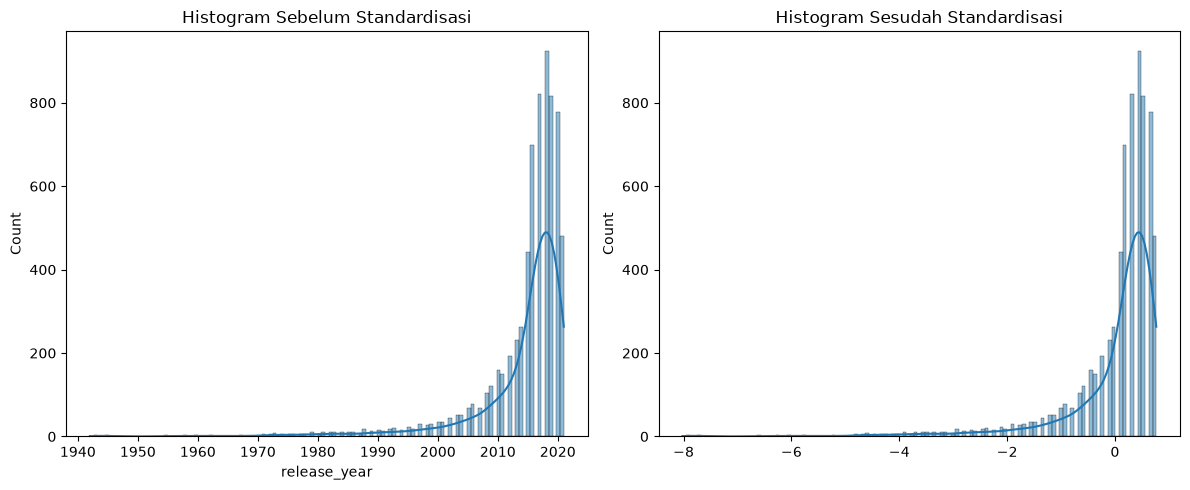

In [20]:
# Histogram sebelum vs sesudah standardisasi (contoh: release_year)
idx = list(x_train.columns).index('release_year')
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(x_train['release_year'], kde=True)
plt.title('Histogram Sebelum Standardisasi')
plt.subplot(1, 2, 2)
sns.histplot(x_train_scaled[:, idx], kde=True)
plt.title('Histogram Sesudah Standardisasi')
plt.tight_layout()
plt.show()

In [ ]:
#5. MODELING
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Model 1: Logistic Regression (pakai data yang sudah di-scale)
LogR = LogisticRegression(max_iter=1000, random_state=184).fit(x_train_scaled, y_train)

# Model 2: Decision Tree
DT = DecisionTreeClassifier(max_depth=6, random_state=184).fit(x_train, y_train)

# Model 3: Random Forest
RF = RandomForestClassifier(n_estimators=200, random_state=184).fit(x_train, y_train)

# Model 4: Gradient Boosting Classifier
GBC = GradientBoostingClassifier(random_state=184).fit(x_train, y_train)

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

def evaluasi(nama, model, xt, yt):
    pred = model.predict(xt)
    return {
        'Model': nama,
        'Accuracy':  accuracy_score(yt, pred),
        'Precision': precision_score(yt, pred),
        'Recall':    recall_score(yt, pred),
        'F1':        f1_score(yt, pred),
    }

hasil = [
    evaluasi('Logistic Regression',     LogR, x_test_scaled, y_test),
    evaluasi('Decision Tree',           DT,   x_test,        y_test),
    evaluasi('Random Forest',           RF,   x_test,        y_test),
    evaluasi('Gradient Boosting',       GBC,  x_test,        y_test),
]
df_results = pd.DataFrame(hasil).set_index('Model').round(4)
df_results

,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.9540,0.9332,0.9140,0.9235
Decision Tree,0.9552,0.9436,0.9065,0.9247
Random Forest,0.9597,0.9462,0.9196,0.9327
Gradient Boosting,0.9586,0.9477,0.9140,0.9305


Model terbaik: Random Forest
              precision    recall  f1-score   support

       Movie       0.97      0.98      0.97      1227
     TV Show       0.95      0.92      0.93       535

    accuracy                           0.96      1762
   macro avg       0.96      0.95      0.95      1762
weighted avg       0.96      0.96      0.96      1762



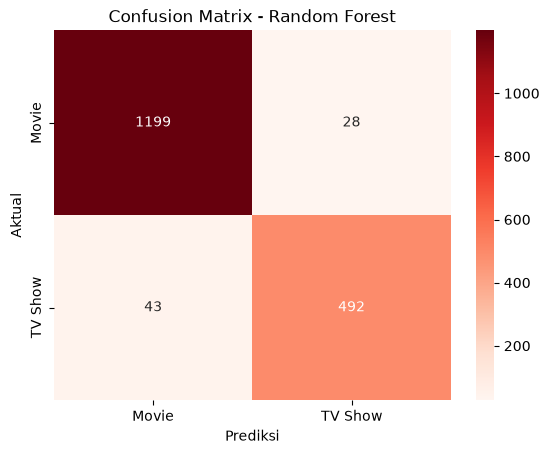

In [23]:
# Confusion matrix & classification report untuk model terbaik (F1 tertinggi)
best_name = df_results['F1'].idxmax()
model_map = {'Logistic Regression': (LogR, x_test_scaled), 'Decision Tree': (DT, x_test),
             'Random Forest': (RF, x_test), 'Gradient Boosting': (GBC, x_test)}
best_model, x_eval = model_map[best_name]
pred_best = best_model.predict(x_eval)

print("Model terbaik:", best_name)
print(classification_report(y_test, pred_best, target_names=['Movie', 'TV Show']))

sns.heatmap(confusion_matrix(y_test, pred_best), annot=True, fmt='d', cmap='Reds',
            xticklabels=['Movie', 'TV Show'], yticklabels=['Movie', 'TV Show'])
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title(f'Confusion Matrix - {best_name}')
plt.show()

In [ ]:
#hitung ukuran dataset 
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("netflix_titles.csv")


print("Ukuran dataset:", df.shape)
print("Nama kolom:", df.columns.tolist())
print(df.head())

Ukuran dataset: (8807, 12)
Nama kolom: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added

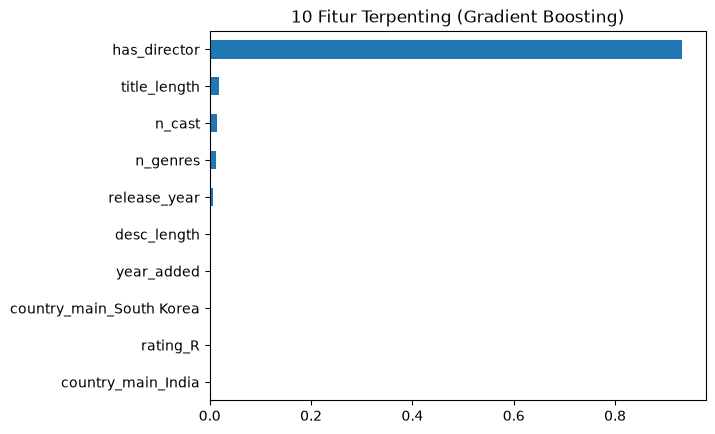

In [24]:
# Fitur terpenting (Gradient Boosting)
imp = pd.Series(GBC.feature_importances_, index=x_train.columns).sort_values(ascending=False)
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title('10 Fitur Terpenting (Gradient Boosting)')
plt.show()

In [25]:
import joblib
import pickle

# Simpan model terbaik ke dalam file
joblib.dump(best_model, 'best_model.joblib')

with open('best_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)